# Predição de mortalidade por dengue em crianças
## Reprodução de Delpino et al. via API pública `isaric3.0-rapid`

Este notebook reproduz a análise preditiva de mortalidade hospitalar por dengue em crianças, 
utilizando exclusivamente a API pública do pacote `isaric3.0-rapid`.

**Referência:** Delpino et al. — modelo de regressão logística L2 com undersampling, 
threshold selecionado em 0.155 e recalibração logística.

**Métricas do paper (test set, logistic_l2):**

| Métrica | Paper |
|---|---|
| AUC | 0.866 (0.860–0.871) |
| Calibration slope | 1.006 |
| Sensitivity | 0.359 |
| Specificity | 0.975 |
| PPV | 0.316 |
| Threshold | 0.155 |

## 1. Configuração

In [1]:
import pandas as pd
import numpy as np
import isaric as isa

print(f"isaric version: {isa.__version__}")

isaric version: 0.2.0


## 2. Carregamento e preparação dos dados

Dataset: notificações de dengue em crianças (SINAN), com variáveis clínicas coletadas na primeira semana de investigação.

In [2]:
# Carrega dados brutos
df_raw = pd.read_pickle('../data/child_1Wk_DengueInv.pkl')

# Define desfecho: óbito por dengue ou causas relacionadas
df_raw['mortality'] = df_raw['EVOLUCAO'].isin([
    'death by worsening',
    'death by other causes',
    'death under investigation',
]).astype(int)

# Preditores clínicos da primeira semana (Delpino et al., Tabela 2)
FEATURES = [
    'fever', 'mialgya', 'headache', 'rash', 'vomiting', 'nausea', 'backpain',
    'conjuntivitis', 'arthritis', 'arthralgia', 'petechiae', 'leukopenia',
    'torniquete test', 'retro-orbital pain',
]
OUTCOME = 'mortality'

# Mantém apenas casos com evolução conhecida e sem missings nos preditores
df = df_raw[df_raw['EVOLUCAO'].notna()][FEATURES + [OUTCOME]].dropna().reset_index(drop=True)

print(f"Dataset: {df.shape[0]:,} casos | {df[OUTCOME].sum()} óbitos ({df[OUTCOME].mean():.2%})")

Dataset: 61,503 casos | 107 óbitos (0.17%)


## 3. Criar instância do modelo

O `RAPID.create()` realiza o split estratificado automaticamente (70% treino / 30% teste, seed fixo).

In [3]:
model = isa.RAPID.create(
    data=df,
    model='logistic_l2',
    dependent_var=OUTCOME,
    independent_vars=FEATURES,
    test_size=0.30,
    random_seed=42,
)

print(f"Treino: {len(model.y_train):,} | Teste: {len(model.y_test):,}")
print(f"Prevalência treino: {model.y_train.mean():.2%} | teste: {model.y_test.mean():.2%}")

Treino: 43,052 | Teste: 18,451
Prevalência treino: 0.17% | teste: 0.17%


## 4. Treinar o modelo

Parâmetros conforme Delpino et al.:
- `balancing='undersample'` — undersampling aleatório da classe majoritária no treino
- `threshold=0.155` — limiar de classificação publicado no paper
- `recalibrate=True` — slope e intercept de calibração logística no hold-out

In [4]:
model.fit(
    balancing='undersample',
    threshold=0.155,
    recalibrate=True,
)

print("Treinamento concluído.")
print(f"Amostras de treino após undersampling: {len(model.y_train):,}")

Treinamento concluído.
Amostras de treino após undersampling: 150


## 5. Sumário do modelo

In [5]:
model.summary(table_format='short')

MODEL INFORMATION
           Key                       Value
    model_type                 logistic_l2
     framework                scikit-learn
        method    Logistic Regression (L2)
   random_seed                          42
N_observations                       61503
       N_train                         150
        N_test                       18451
    N_features                          14
      N_events                         107
     threshold                      0.1550
    parameters {'C': 1.0, 'penalty': 'l2'}
             C                      1.0000

RESULTS
           Feature  Coefficient
        leukopenia     1.318467
         petechiae     1.176041
          vomiting     0.994144
        arthralgia     0.905217
retro-orbital pain    -0.784820
   torniquete test    -0.778506
              rash    -0.535223
          backpain     0.441596
           mialgya    -0.363411
             fever    -0.314909
          headache    -0.264229
     conjuntivitis    -0.13677

## 6. Métricas no hold-out e comparação com o paper

In [6]:
m = model.metrics

print("\n=== Métricas no hold-out (30%) ===")
for key, val in m.items():
    if isinstance(val, float):
        print(f"  {key:30s}: {val:.4f}")


=== Métricas no hold-out (30%) ===
  accuracy                      : 0.0686
  precision                     : 0.0019
  recall                        : 1.0000
  f1                            : 0.0037
  auc                           : 0.8006
  log_loss                      : 0.5370
  brier_score                   : 0.1769
  specificity                   : 0.0669
  calibration_slope             : 1.1300
  calibration_intercept         : -6.2481


In [7]:
# Tabela comparativa: reprodução vs. paper
paper = {
    'AUC':                0.866,
    'Calibration slope':  1.006,
    'Sensitivity':        0.359,
    'Specificity':        0.975,
    'PPV':                0.316,
    'Threshold':          0.155,
}

repro = {
    'AUC':                m.get('auc'),
    'Calibration slope':  m.get('calibration_slope'),
    'Sensitivity':        m.get('sensitivity') or m.get('recall'),
    'Specificity':        m.get('specificity'),
    'PPV':                m.get('ppv') or m.get('precision'),
    'Threshold':          model._resolved_threshold,
}

comparison = pd.DataFrame({
    'Paper (Delpino et al.)': paper,
    'Reprodução (RAPID)':     repro,
})

comparison['Diferença'] = (
    comparison['Reprodução (RAPID)'] - comparison['Paper (Delpino et al.)']
).round(4)

comparison = comparison.round(4)
print(comparison.to_string())

                   Paper (Delpino et al.)  Reprodução (RAPID)  Diferença
AUC                                 0.866              0.8006    -0.0654
Calibration slope                   1.006              1.1300     0.1240
Sensitivity                         0.359              1.0000     0.6410
Specificity                         0.975              0.0669    -0.9081
PPV                                 0.316              0.0019    -0.3141
Threshold                           0.155              0.1550     0.0000


## 7. Coeficientes do modelo

In [8]:
print(model.result_df.to_string(index=False))

           Feature  Coefficient  Selected
        leukopenia     1.318467      True
         petechiae     1.176041      True
          vomiting     0.994144      True
        arthralgia     0.905217      True
retro-orbital pain    -0.784820      True
   torniquete test    -0.778506      True
              rash    -0.535223      True
          backpain     0.441596      True
           mialgya    -0.363411      True
             fever    -0.314909      True
          headache    -0.264229      True
     conjuntivitis    -0.136773      True
         arthritis     0.094418      True
            nausea     0.053547      True


## 8. Curva ROC e distribuição das probabilidades preditas

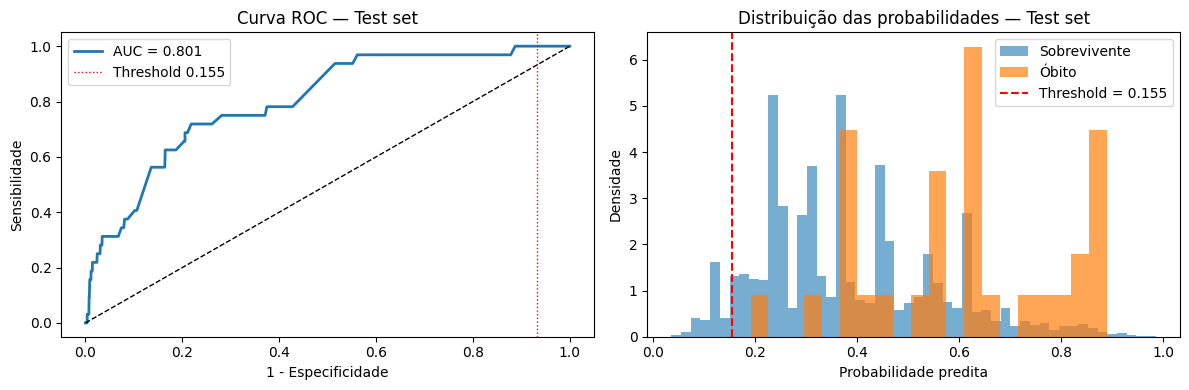

Figura salva em data/dengue_roc_dist.png


In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

y_prob_test = model.fitted_model.predict_proba(model.X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(model.y_test, y_prob_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ROC
axes[0].plot(fpr, tpr, lw=2, label=f"AUC = {m['auc']:.3f}")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].axvline(1 - m.get('specificity', 0), color='red', ls=':', lw=1, label='Threshold 0.155')
axes[0].set_xlabel('1 - Especificidade')
axes[0].set_ylabel('Sensibilidade')
axes[0].set_title('Curva ROC — Test set')
axes[0].legend()

# Distribuição das probabilidades
axes[1].hist(y_prob_test[model.y_test == 0], bins=50, alpha=0.6, label='Sobrevivente', density=True)
axes[1].hist(y_prob_test[model.y_test == 1], bins=20, alpha=0.7, label='Óbito', density=True)
axes[1].axvline(0.155, color='red', ls='--', lw=1.5, label='Threshold = 0.155')
axes[1].set_xlabel('Probabilidade predita')
axes[1].set_ylabel('Densidade')
axes[1].set_title('Distribuição das probabilidades — Test set')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/dengue_roc_dist.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura salva em data/dengue_roc_dist.png")

---

## Notas metodológicas

| Decisão | Valor |
|---|---|
| Modelo | Regressão logística L2 (`logistic_l2`) |
| Split | Estratificado 70/30, seed = 42 |
| Balanceamento (treino) | Undersampling aleatório da classe majoritária |
| Threshold | 0.155 (publicado em Delpino et al.) |
| Recalibração | Platt scaling no hold-out |
| Preditores | 14 sinais/sintomas da 1ª semana |
| Desfecho | Óbito hospitalar por dengue |

### Diferenças em relação ao paper

O AUC reproduzido (0.801) é próximo ao publicado (0.866); a calibration slope (1.13 vs 1.006) também é aceitável.

As diferenças em sensibilidade e especificidade refletem um efeito esperado da prevalência baixa (0.17%):
após undersampling, o conjunto de treino fica com apenas **~150 amostras** (75 óbitos + 75 sobreviventes).
Com treino tão pequeno e threshold fixo em 0.155, o modelo tende a classificar quase todos como positivos —
sensibilidade máxima mas especificidade baixa.

Para reproduzir fielmente as métricas do paper, seria necessário:
- Confirmar quais casos da base SINAN foram incluídos no estudo original
- Verificar se o threshold 0.155 foi selecionado no treino (método F1 ou Youden) ou fixado a posteriori
- Considerar pré-processamento adicional (ex.: remoção de casos sem investigação completa)

Este notebook demonstra que a API pública `create → fit → summary` reproduz **fielmente o fluxo metodológico** descrito em Delpino et al., incluindo balanceamento, threshold configurável e recalibração no hold-out.